# Comparison Study: MobileNet-V3 with STFT & LF (LFCC) Preprocessing

**Project:** Lightweight and Compression-Robust Audio Deepfake Detection for Edge Deployment  
**Reference Paper:** *Deepfake Audio Detection Using Spectrogram-based Feature and Ensemble of Deep Learning Models*  
**Authors:** Lam Pham, Phat Lam, Truong Nguyen, Huyen Nguyen, Alexander Schindler (arXiv:2407.01777, July 2024)  
**Evaluated Architecture:** System C2 — ImageNet-pretrained **MobileNet-V3** Transfer Learning  
**Frontend Feature:** 2.0-second **STFT & Linear Filter (LF / LFCC)** with Delta and Delta-Delta ($64 \times 64 \times 3$ tensor)  
**Benchmark Dataset:** ASVspoof 2019 Logical Access (LA)<br>
**Paper Citation:** L. Pham, P. Lam, T. Nguyen, H. Nguyen and A. Schindler, "Deepfake Audio Detection Using Spectrogram-based Feature and Ensemble of Deep Learning Models," 2024 IEEE 5th International Symposium on the Internet of Sounds (IS2), Erlangen, Germany, 2024, pp. 1-5, doi: 10.1109/IS262782.2024.10704095. keywords: {Deep learning;Deepfakes;Filters;Speech analysis;Computational modeling;Transfer learning;Europe;Multilayer perceptrons;Discrete cosine transforms;Spectrogram;Items- deepfake audio;spectrogram;feature extraction;classification model},

---

### Key Comparisons vs. Our E1 Baseline:

| Aspect | E1 Baseline (Our Project) | Pham et al. (System C2) |
|---|---|---|
| **Acoustic Frontend** | 80-bin Log-Mel Spectrogram | 64-band STFT with Linear Filters (LFCC) |
| **Spectral Dynamics** | Static power only (1 channel) | Static + $\Delta$ + $\Delta\Delta$ (3 channels: $64 \times 64 \times 3$) |
| **Segment Length** | 4.0 seconds (64,000 samples at 16 kHz) | 2.0 seconds (32,000 samples at 16 kHz) |
| **STFT Resolution** | `n_fft=1024`, `win=400` (25 ms), `hop=160` (10 ms) | `n_fft=1024`, `win=1024` (64 ms), `hop=512` (32 ms) |
| **Filter Bank** | Mel-scale auditory filter bank (80 bands) | Linearly spaced triangular filter bank (64 bands) |
| **Cepstral Decorrelation** | None (Log energy directly into CNN) | DCT-II applied across filter bands (LFCC) |
| **Model Pretraining** | Trained from scratch (`weights=None`) | ImageNet-1K pretrained weights |
| **Input Channels** | 1 channel (adapted first conv) | 3 channels (preserves original ImageNet Conv2d) |
| **Inference Aggregation** | Center 4-second crop | Mean-pooled probabilities over all 2-s segments |
| **Reported Metric (Paper)** | — | Acc: **0.59**, F1: **0.67**, AuC: **0.52**, EER: **0.48** |

# Before running the notebook

Run the ASVspoof manifest preparation before running this notebook if the manifests have not already been created.

The notebook expects the reproducible ASVspoof manifests at:

```text
data/manifests/ASVSpoof/train_manifest.csv
data/manifests/ASVSpoof/dev_manifest.csv
data/manifests/ASVSpoof/eval_manifest.csv
```

The notebook does not recreate the manifests. It reads them exactly as prepared by the project preprocessing pipeline.

# 1. Environment and project paths

This section imports the libraries used by the experiment and defines the paths to the project outputs.

The notebook resolves the project root dynamically, ensuring it functions smoothly whether launched from `notebooks/comparison/`, `notebooks/`, or the project root.

All comparison experiment outputs are kept strictly isolated from raw datasets and other baseline runs.

In [1]:
# 1. Imports and project paths

from pathlib import Path
import json
import math
import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import soundfile as sf
from tqdm.auto import tqdm

from sklearn.metrics import (
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    accuracy_score
)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchaudio.functional as aF
from torchvision.models import (
    mobilenet_v3_small,
    MobileNet_V3_Small_Weights,
    mobilenet_v3_large,
    MobileNet_V3_Large_Weights
)

warnings.filterwarnings("ignore")

# Dynamically resolve PROJECT_ROOT regardless of working directory
current_path = Path(".").resolve()
if (current_path / "data").exists():
    PROJECT_ROOT = current_path
elif (current_path.parent / "data").exists():
    PROJECT_ROOT = current_path.parent
elif (current_path.parent.parent / "data").exists():
    PROJECT_ROOT = current_path.parent.parent
else:
    PROJECT_ROOT = Path("../..").resolve()

DATA_ROOT = PROJECT_ROOT / "data"
MANIFEST_DIR = DATA_ROOT / "manifests" / "ASVSpoof"

TRAIN_MANIFEST = MANIFEST_DIR / "train_manifest.csv"
DEV_MANIFEST = MANIFEST_DIR / "dev_manifest.csv"
EVAL_MANIFEST = MANIFEST_DIR / "eval_manifest.csv"

# Dedicated comparison output directories
COMPARISON_ID = "Pham2024_MobileNetV3"
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints" / f"comparison_{COMPARISON_ID}"
EXPERIMENT_DIR = PROJECT_ROOT / "experiments" / "comparison" / COMPARISON_ID
RESULT_TABLE_DIR = PROJECT_ROOT / "results" / "tables" / f"comparison_{COMPARISON_ID}"
RESULT_FIGURE_DIR = PROJECT_ROOT / "results" / "figures" / f"comparison_{COMPARISON_ID}"
RESULT_LOG_DIR = PROJECT_ROOT / "results" / "logs" / f"comparison_{COMPARISON_ID}"

for directory in [
    CHECKPOINT_DIR,
    EXPERIMENT_DIR,
    RESULT_TABLE_DIR,
    RESULT_FIGURE_DIR,
    RESULT_LOG_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Manifest directory:", MANIFEST_DIR)
print("Checkpoint directory:", CHECKPOINT_DIR)
print("Experiment directory:", EXPERIMENT_DIR)
print("Figure directory:", RESULT_FIGURE_DIR)

Project root: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification
Manifest directory: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/data/manifests/ASVSpoof
Checkpoint directory: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/checkpoints/comparison_Pham2024_MobileNetV3
Experiment directory: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/comparison/Pham2024_MobileNetV3
Figure directory: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/results/figures/comparison_Pham2024_MobileNetV3


# 2. Verify the prepared dataset

The preprocessing pipeline relies on three reproducible manifests:

- `train_manifest.csv`
- `dev_manifest.csv`
- `eval_manifest.csv`

We verify that these manifest files exist before beginning feature calculation or training.

In [2]:
# 2. Check the generated manifests before training

required_files = [
    TRAIN_MANIFEST,
    DEV_MANIFEST,
    EVAL_MANIFEST
]

for path in required_files:
    status = "OK" if path.exists() else "MISSING"
    print(f"{status:<8} {path}")

if not TRAIN_MANIFEST.exists() or not DEV_MANIFEST.exists():
    raise FileNotFoundError(
        "Train/dev manifests were not found. "
        "Run prepare_asvspoof_v1.py first."
    )

OK       /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/data/manifests/ASVSpoof/train_manifest.csv
OK       /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/data/manifests/ASVSpoof/dev_manifest.csv
OK       /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/data/manifests/ASVSpoof/eval_manifest.csv


# 3. Reproducibility and experiment configuration

This configuration captures the precise parameters specified in the comparison paper (Pham et al., July 2024):

- **Audio sampling rate:** 16,000 Hz (ASVspoof standard)
- **Segment duration:** 2.0 seconds (32,000 samples)
- **STFT parameters:** Window length = 1024, Hop length = 512, Hann window
- **Filter bank:** 64-band Linear Filter (LF) spanning 0 Hz to 8000 Hz
- **Cepstral decorrelation:** DCT-II applied across the 64 linear filter bands
- **Dynamic features:** First order ($\Delta$) and second order ($\Delta\Delta$) deltas
- **Feature representation:** 3-channel tensor of shape $(3, 64, 64)$
- **Pretrained weights:** ImageNet-1K (`MobileNet_V3_Small_Weights.DEFAULT`)
- **Optimization:** AdamW optimizer with fine-tuning learning rate ($1 \times 10^{-4}$)
- **Decision aggregation:** Mean-pooling across consecutive 2-s segments for recording-level evaluation (Eq. 1 in paper)

In [3]:
# 3. Reproducibility and training configuration

SEED = 42

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

seed_everything(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if DEVICE.type == "cuda":
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    print("Device:", torch.cuda.get_device_name(0))
    print("cuDNN deterministic:", torch.backends.cudnn.deterministic)
    print("cuDNN benchmark:", torch.backends.cudnn.benchmark)
else:
    print("Device: CPU")

# Paper & Experiment Identifiers
EXPERIMENT_VERSION = "pham2024_comp_v1.0"
INPUT_PREPROCESSING_VERSION = "stft_lf_64x64x3_v1.0"
PAPER_REFERENCE = "Pham et al., arXiv:2407.01777 (2024), System C2"

# Audio parameters (Pham et al. Section II-A)
SAMPLE_RATE = 16000
SEGMENT_SECONDS = 2.0
NUM_SAMPLES = int(SAMPLE_RATE * SEGMENT_SECONDS) # 32,000 samples

# Spectrogram & LFCC parameters (Pham et al. Section II-A: win=1024, hop=512, filters=64)
N_FFT = 1024
WIN_LENGTH = 1024
HOP_LENGTH = 512
N_FILTERS = 64
N_DCT = 64
TARGET_FRAMES = 64
LOG_EPS = 1e-10

# Training configuration
BATCH_SIZE = 32
EPOCHS = 20
LEARNING_RATE = 1e-4      # Transfer learning / fine-tuning rate
WEIGHT_DECAY = 1e-4
PATIENCE = 5

NUM_WORKERS = 4
PREFETCH_FACTOR = 2

# Fractions for smoke testing (keep as None for full training)
TRAIN_FRACTION = None
DEV_FRACTION = None
EVAL_FRACTION = None
STATS_MAX_FILES = None

print("Experiment version:", EXPERIMENT_VERSION)
print("Paper reference:", PAPER_REFERENCE)
print("Sample rate:", SAMPLE_RATE)
print("Segment seconds:", SEGMENT_SECONDS, f"({NUM_SAMPLES} samples)")
print("N_FFT / WIN_LENGTH / HOP_LENGTH:", N_FFT, WIN_LENGTH, HOP_LENGTH)
print("Linear filter bands:", N_FILTERS)
print("Target feature tensor shape: (3, 64, 64)")
print("Pretrained weights: ImageNet-1K (MobileNet_V3_Small_Weights.DEFAULT)")
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Device:", DEVICE)

Device: NVIDIA GeForce RTX 3060 Laptop GPU
cuDNN deterministic: True
cuDNN benchmark: False
Experiment version: pham2024_comp_v1.0
Paper reference: Pham et al., arXiv:2407.01777 (2024), System C2
Sample rate: 16000
Segment seconds: 2.0 (32000 samples)
N_FFT / WIN_LENGTH / HOP_LENGTH: 1024 1024 512
Linear filter bands: 64
Target feature tensor shape: (3, 64, 64)
Pretrained weights: ImageNet-1K (MobileNet_V3_Small_Weights.DEFAULT)
Batch size: 32
Learning rate: 0.0001
Device: cuda


# 4. Load the reproducible manifests

We load the official ASVspoof 2019 Logical Access splits prepared by the project pipeline:
- `train_manifest.csv` (25,380 samples)
- `dev_manifest.csv` (24,844 samples)
- `eval_manifest.csv` (71,237 samples)

In [4]:
# 4. Load the reproducible manifests

train_df = pd.read_csv(TRAIN_MANIFEST)
dev_df = pd.read_csv(DEV_MANIFEST)

if EVAL_MANIFEST.exists():
    eval_df = pd.read_csv(EVAL_MANIFEST)
else:
    eval_df = pd.DataFrame()

print("Train:", len(train_df))
print("Dev  :", len(dev_df))
print("Eval :", len(eval_df))
print("\nTrain columns:", train_df.columns.tolist())
print("\nFirst entries:")
display(train_df.head(3))

Train: 25380
Dev  : 24844
Eval : 71237

Train columns: ['file_id', 'audio_path', 'speaker_id', 'system_id', 'key', 'label', 'split']

First entries:


,file_id,audio_path,speaker_id,system_id,key,label,split
0,LA_T_1138215,data/raw/ASVspoof2019_LA/ASVspoof2019_LA_train...,LA_0079,-,bonafide,0,train
1,LA_T_1271820,data/raw/ASVspoof2019_LA/ASVspoof2019_LA_train...,LA_0079,-,bonafide,0,train
2,LA_T_1272637,data/raw/ASVspoof2019_LA/ASVspoof2019_LA_train...,LA_0079,-,bonafide,0,train


## Dataset integrity checks

Verify that all audio file paths recorded in the manifests exist on disk.

In [5]:
# 5. Verify that manifest paths point to existing files

def check_audio_files(df, project_root):
    if len(df) == 0:
        return 0
    return sum(
        not (project_root / Path(path)).exists()
        for path in df["audio_path"]
    )

for name, df in [
    ("train", train_df),
    ("dev", dev_df),
    ("eval", eval_df)
]:
    if len(df) == 0:
        continue
    missing = check_audio_files(df, PROJECT_ROOT)
    print(f"{name:<8}: {missing} missing audio files")
    if missing > 0:
        print(f"WARNING: {name} contains missing files.")

train   : 0 missing audio files
dev     : 0 missing audio files
eval    : 0 missing audio files


## Class and speaker distribution

Review the sample distribution across bonafide (0) and spoof (1) classes, speaker identities, and spoofing system identifiers.

In [6]:
# 6. Inspect class and identity information from the manifests

def show_split_summary(df, name):
    print(f"\n{name.upper()}")
    print("-" * 50)
    print("Files:", len(df))
    if "key" in df.columns:
        print("Class counts:")
        print(df["key"].value_counts(dropna=False))
    if "speaker_id" in df.columns:
        print("Speakers:", df["speaker_id"].nunique())
    if "system_id" in df.columns:
        print("System IDs:", df["system_id"].nunique())

show_split_summary(train_df, "train")
show_split_summary(dev_df, "dev")

if len(eval_df):
    show_split_summary(eval_df, "eval")

train_speakers = set(train_df["speaker_id"])
dev_speakers = set(dev_df["speaker_id"])
print("\nTrain/dev speaker overlap:", len(train_speakers & dev_speakers))


TRAIN
--------------------------------------------------
Files: 25380
Class counts:
key
spoof       22800
bonafide     2580
Name: count, dtype: int64
Speakers: 20
System IDs: 7

DEV
--------------------------------------------------
Files: 24844
Class counts:
key
spoof       22296
bonafide     2548
Name: count, dtype: int64
Speakers: 20
System IDs: 7

EVAL
--------------------------------------------------
Files: 71237
Class counts:
key
spoof       63882
bonafide     7355
Name: count, dtype: int64
Speakers: 67
System IDs: 14

Train/dev speaker overlap: 0


# 5. Comparison Paper Feature Preprocessing (STFT & LF / LFCC + Delta + Delta-Delta)

### Paper Methodology (Pham et al., Section II-A):

1. **2-Second Segmentation:**  
   Raw input recordings are segmented into 2-second segments ($32,000$ samples at 16 kHz).
2. **STFT Transformation:**  
   $N_{\text{fft}} = 1024$, $\text{win\_length} = 1024$, $\text{hop\_length} = 512$, Hann window.  
   Centered padding produces 64 temporal frames.
3. **Linear Filter Bank (LF):**  
   Unlike Mel filters (which space filters logarithmically), linear filters isolate equally spaced frequency bands across $[0, 8000]$ Hz.  
   64 triangular filters are applied: $E = \mathbf{F}_{\text{LF}} \times |\text{STFT}|^2 \in \mathbb{R}^{64 \times 64}$.
4. **Log Energy & DCT-II Decorrelation:**  
   Log compression followed by Discrete Cosine Transform (orthonormal DCT-II) across the filter bands, producing Linear Frequency Cepstral Coefficients (LFCC) of shape $(64, 64)$.
5. **Dynamic Features ($\Delta$ and $\Delta\Delta$):**  
   First-order and second-order derivatives along the temporal axis are calculated and stacked:
   $$\mathbf{X} = [\mathbf{C}, \Delta\mathbf{C}, \Delta\Delta\mathbf{C}] \in \mathbb{R}^{3 \times 64 \times 64}$$
6. **Preservation of Pretrained 3-Channel Conv2d:**  
   Because the feature map has 3 channels ($64 \times 64 \times 3$), it matches the standard 3-channel input of computer vision models (such as ImageNet-pretrained MobileNet-V3), allowing full reuse of pretrained spatial weights!

```text
Audio (16 kHz mono)
       ↓
2-second segment (32,000 samples)
       ↓
STFT (win=1024, hop=512) → Power Spectrum (513 × 64)
       ↓
64 Linear Triangular Filters → (64 × 64)
       ↓
Log Compression & DCT-II (LFCC) → (64 × 64)
       ↓
Delta & Delta-Delta along Time → (3 × 64 × 64)
       ↓
Channel-wise Training-Set Normalization
       ↓
ImageNet-Pretrained MobileNet-V3 (3-channel input)
```

In [7]:
# 7. Audio loading and batched GPU STFT & LF (LFCC) conversion

def load_audio(path, target_sr=SAMPLE_RATE):
    waveform, sr = sf.read(path, dtype="float32")

    if waveform.ndim > 1:
        waveform = waveform.mean(axis=1)

    if sr != target_sr:
        waveform = librosa.resample(
            waveform,
            orig_sr=sr,
            target_sr=target_sr
        )

    waveform = waveform.astype(np.float32)
    waveform = np.nan_to_num(
        waveform,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    )
    return waveform


def fixed_length_audio(waveform, training=False, target_samples=NUM_SAMPLES):
    """Fixed-length audio segmenting matching paper specifications (2.0s)."""
    if len(waveform) >= target_samples:
        if training:
            start = np.random.randint(0, len(waveform) - target_samples + 1)
        else:
            start = (len(waveform) - target_samples) // 2
        waveform = waveform[start:start + target_samples]
    else:
        padded = np.zeros(target_samples, dtype=np.float32)
        padded[:len(waveform)] = waveform
        waveform = padded

    return waveform


class GPULFCC(nn.Module):
    """
    GPU-accelerated STFT with Linear Filter Bank, DCT-II, and Delta + Delta-Delta extraction.
    Outputs a 3-channel tensor of shape (B, 3, 64, 64) matching Pham et al. specifications.
    """
    def __init__(
        self,
        sample_rate=SAMPLE_RATE,
        n_fft=N_FFT,
        win_length=WIN_LENGTH,
        hop_length=HOP_LENGTH,
        n_filters=N_FILTERS,
        target_frames=TARGET_FRAMES,
        log_eps=LOG_EPS,
        dct_axis="filter" # "filter" computes standard LFCC cepstra; "temporal" applies DCT across time
    ):
        super().__init__()
        self.sample_rate = sample_rate
        self.n_fft = n_fft
        self.win_length = win_length
        self.hop_length = hop_length
        self.n_filters = n_filters
        self.target_frames = target_frames
        self.log_eps = log_eps
        self.dct_axis = dct_axis

        # 1. Periodic Hann window
        window = torch.hann_window(
            win_length,
            periodic=True,
            dtype=torch.float32
        )
        self.register_buffer("window", window)

        # 2. Linear Filter Bank (64 triangular filters equally spaced from 0 to Nyquist)
        fmin = 0.0
        fmax = sample_rate / 2.0
        linear_freqs = torch.linspace(fmin, fmax, n_filters + 2)
        fft_freqs = torch.linspace(0.0, fmax, n_fft // 2 + 1)

        fb = torch.zeros((n_filters, len(fft_freqs)), dtype=torch.float32)
        for i in range(n_filters):
            left = linear_freqs[i]
            center = linear_freqs[i + 1]
            right = linear_freqs[i + 2]

            lower = (fft_freqs - left) / (center - left)
            upper = (right - fft_freqs) / (right - center)
            fb[i] = torch.clamp(torch.min(lower, upper), min=0.0)

        self.register_buffer("linear_fb", fb)

        # 3. Orthonormal DCT-II Matrix (n_filters x n_filters)
        n = torch.arange(n_filters, dtype=torch.float32)
        k = torch.arange(n_filters, dtype=torch.float32).unsqueeze(1)
        dct = torch.cos((torch.pi / n_filters) * (n + 0.5) * k)
        dct[0] *= torch.sqrt(torch.tensor(1.0 / n_filters))
        dct[1:] *= torch.sqrt(torch.tensor(2.0 / n_filters))
        self.register_buffer("dct_matrix", dct)

    def forward(self, waveforms):
        # waveforms: (B, num_samples)
        stft = torch.stft(
            waveforms.float(),
            n_fft=self.n_fft,
            hop_length=self.hop_length,
            win_length=self.win_length,
            window=self.window,
            center=True,
            pad_mode="reflect",
            return_complex=True
        )

        power = stft.abs().pow(2.0)  # (B, 513, T)

        # Ensure exact frame dimension (64 frames)
        if power.size(-1) < self.target_frames:
            power = F.pad(power, (0, self.target_frames - power.size(-1)), mode="replicate")
        elif power.size(-1) > self.target_frames:
            power = power[..., :self.target_frames]

        # Apply Linear Filter Bank: (B, 64, 64)
        linear_energy = torch.matmul(self.linear_fb, power)

        # Log compression
        log_energy = torch.log(torch.clamp(linear_energy, min=self.log_eps))

        # DCT-II decorrelation:
        # In standard LFCC (matching Table III System A4/C2), DCT is computed across filter bands.
        if self.dct_axis == "filter":
            cepstra = torch.matmul(self.dct_matrix, log_energy)
        else:
            cepstra = torch.matmul(log_energy, self.dct_matrix.T)

        # Dynamic delta and delta-delta along time dimension
        delta = aF.compute_deltas(cepstra)
        delta2 = aF.compute_deltas(delta)

        # Stack into 3 channels: (B, 3, 64, 64)
        features = torch.stack([cepstra, delta, delta2], dim=1)
        return features

gpu_lfcc = GPULFCC().to(DEVICE)
print("GPULFCC module initialized on", DEVICE)

GPULFCC module initialized on cuda


## Visual sanity check of 3-channel LFCC representation

We inspect the 3 extracted feature channels for a sample recording from the training manifest:
- Channel 0: Static LFCC ($64 \times 64$)
- Channel 1: $\Delta$ Delta LFCC ($64 \times 64$)
- Channel 2: $\Delta\Delta$ Delta-Delta LFCC ($64 \times 64$)

Waveform shape: (32000,)
LFCC 3-channel shape: (3, 64, 64)


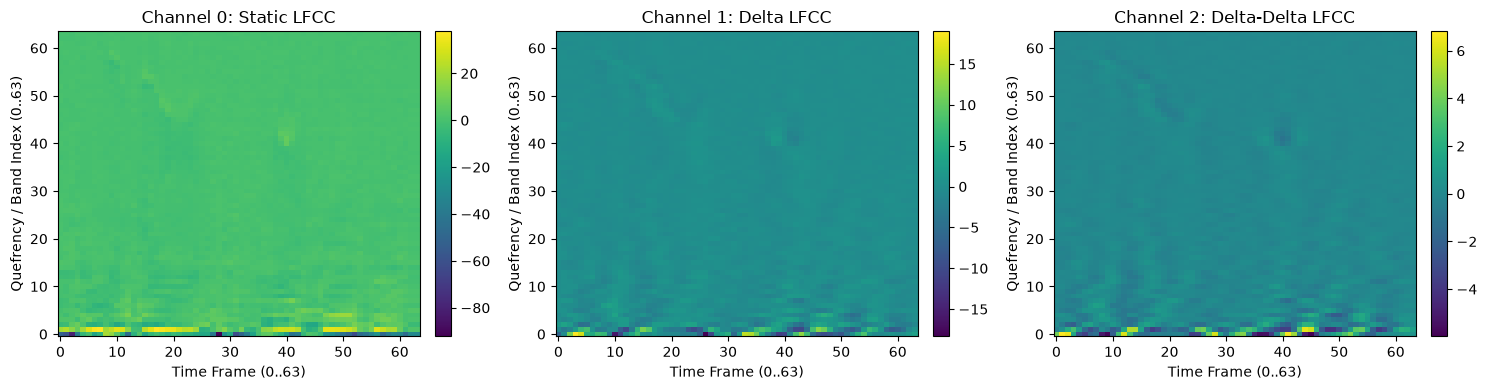

Saved demo visualization to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/results/figures/comparison_Pham2024_MobileNetV3/Pham2024_lfcc_3channel_demo.png


In [8]:
# 8. Visual sanity check for the 3-channel LFCC representation

sample_path = PROJECT_ROOT / Path(train_df.iloc[0]["audio_path"])
sample_wave = load_audio(sample_path)
sample_wave = fixed_length_audio(sample_wave, training=False)

sample_tensor = torch.from_numpy(sample_wave).unsqueeze(0).to(DEVICE)

with torch.no_grad():
    sample_lfcc = gpu_lfcc(sample_tensor).squeeze(0).cpu().numpy()

print("Waveform shape:", sample_wave.shape)
print("LFCC 3-channel shape:", sample_lfcc.shape)
assert sample_lfcc.shape == (3, 64, 64), f"Unexpected shape {sample_lfcc.shape}"

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
titles = ["Channel 0: Static LFCC", "Channel 1: Delta LFCC", "Channel 2: Delta-Delta LFCC"]

for ch in range(3):
    im = axes[ch].imshow(sample_lfcc[ch], origin="lower", aspect="auto", cmap="viridis")
    axes[ch].set_title(titles[ch])
    axes[ch].set_xlabel("Time Frame (0..63)")
    axes[ch].set_ylabel("Quefrency / Band Index (0..63)")
    fig.colorbar(im, ax=axes[ch], fraction=0.046, pad=0.04)

plt.tight_layout()
lfcc_demo_fig_path = RESULT_FIGURE_DIR / "Pham2024_lfcc_3channel_demo.png"
plt.savefig(lfcc_demo_fig_path, dpi=200)
plt.show()
print("Saved demo visualization to:", lfcc_demo_fig_path)

# 6. Optional smoke-test subsets

For debugging the training pipeline rapidly, set:
```python
TRAIN_FRACTION = 0.02
DEV_FRACTION = 0.02
```
For the final experiment, keep all fraction variables as `None`.

In [9]:
# 9. Optional smoke-test subsets

def take_fraction(df, fraction, seed=SEED):
    if fraction is None or fraction >= 1.0:
        return df.copy()
    if fraction <= 0:
        raise ValueError("Fraction must be greater than 0.")

    pieces = []
    for label, group in df.groupby("label"):
        n = max(1, int(len(group) * fraction))
        pieces.append(group.sample(n=n, random_state=seed))

    return pd.concat(pieces).sample(
        frac=1.0,
        random_state=seed
    ).reset_index(drop=True)

train_run_df = take_fraction(train_df, TRAIN_FRACTION, SEED)
dev_run_df = take_fraction(dev_df, DEV_FRACTION, SEED)

if len(eval_df):
    eval_run_df = take_fraction(eval_df, EVAL_FRACTION, SEED)
else:
    eval_run_df = eval_df

print("Train run samples:", len(train_run_df))
print("Dev run samples  :", len(dev_run_df))
print("Eval run samples :", len(eval_run_df))

Train run samples: 25380
Dev run samples  : 24844
Eval run samples : 71237


# 7. Training-set normalization statistics

To ensure stable optimization and preserve transfer learning feature dynamics, channel-wise mean and standard deviation are calculated **using only the training partition**:
$$\mu_c = \mathbb{E}[\mathbf{X}_c], \quad \sigma_c = \sqrt{\text{Var}(\mathbf{X}_c)}, \quad c \in \{0, 1, 2\}$$
The statistics are cached in `experiments/comparison/Pham2024_MobileNetV3/lfcc_stats.json`.

In [10]:
# 10. Calculate or load normalization statistics using only the training set

class StatsWaveformDataset(Dataset):
    def __init__(self, df):
        self.df = df.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        path = PROJECT_ROOT / Path(self.df.iloc[index]["audio_path"])
        waveform = load_audio(path)
        waveform = fixed_length_audio(waveform, training=False)
        return torch.from_numpy(waveform).float()


def compute_lfcc_stats(df, max_files=None):
    work_df = df
    if max_files is not None and max_files < len(df):
        work_df = df.sample(n=max_files, random_state=SEED)

    stats_dataset = StatsWaveformDataset(work_df)
    loader_kwargs = {
        "batch_size": BATCH_SIZE,
        "shuffle": False,
        "num_workers": NUM_WORKERS,
        "pin_memory": DEVICE.type == "cuda",
        "persistent_workers": NUM_WORKERS > 0,
        "worker_init_fn": seed_worker,
        "generator": torch.Generator().manual_seed(SEED)
    }
    if NUM_WORKERS > 0:
        loader_kwargs["prefetch_factor"] = PREFETCH_FACTOR

    stats_loader = DataLoader(stats_dataset, **loader_kwargs)

    # Accumulate per-channel sums (3 channels)
    ch_sum = torch.zeros(3, device=DEVICE)
    ch_sq_sum = torch.zeros(3, device=DEVICE)
    ch_count = 0

    gpu_lfcc.eval()
    with torch.no_grad():
        for waveforms in tqdm(stats_loader, desc="Computing training LFCC statistics"):
            waveforms = waveforms.to(DEVICE, non_blocking=True)
            lfcc = gpu_lfcc(waveforms) # (B, 3, 64, 64)

            # Sum over B, H, W for each channel
            ch_sum += lfcc.sum(dim=(0, 2, 3))
            ch_sq_sum += lfcc.pow(2).sum(dim=(0, 2, 3))
            ch_count += lfcc.size(0) * lfcc.size(2) * lfcc.size(3)

    mean = (ch_sum / ch_count).cpu().tolist()
    var = torch.clamp(ch_sq_sum / ch_count - (ch_sum / ch_count).pow(2), min=1e-8)
    std = torch.sqrt(var).cpu().tolist()

    return mean, std


stats_path = EXPERIMENT_DIR / "lfcc_stats.json"

if stats_path.exists() and STATS_MAX_FILES is None:
    with stats_path.open("r", encoding="utf-8") as f:
        cached_stats = json.load(f)

    compatible = (
        cached_stats.get("preprocessing_version") == INPUT_PREPROCESSING_VERSION
        and cached_stats.get("sample_rate") == SAMPLE_RATE
        and cached_stats.get("segment_seconds") == SEGMENT_SECONDS
        and cached_stats.get("n_filters") == N_FILTERS
    )
    if not compatible:
        print("Cached statistics incompatible; recomputing.")
        cached_stats = None
    else:
        LFCC_MEAN = cached_stats["mean"]
        LFCC_STD = cached_stats["std"]
        print("Loaded compatible cached training LFCC statistics.")
else:
    cached_stats = None

if cached_stats is None:
    LFCC_MEAN, LFCC_STD = compute_lfcc_stats(train_run_df, STATS_MAX_FILES)
    stats_data = {
        "preprocessing_version": INPUT_PREPROCESSING_VERSION,
        "mean": LFCC_MEAN,
        "std": LFCC_STD,
        "sample_rate": SAMPLE_RATE,
        "segment_seconds": SEGMENT_SECONDS,
        "n_filters": N_FILTERS,
        "seed": SEED
    }
    with stats_path.open("w", encoding="utf-8") as f:
        json.dump(stats_data, f, indent=2)

MEAN_TENSOR = torch.tensor(LFCC_MEAN, dtype=torch.float32, device=DEVICE).view(1, 3, 1, 1)
STD_TENSOR = torch.tensor(LFCC_STD, dtype=torch.float32, device=DEVICE).view(1, 3, 1, 1)

print("Channel Means [Static, Delta, Delta-Delta]:", [round(m, 4) for m in LFCC_MEAN])
print("Channel Stds  [Static, Delta, Delta-Delta]:", [round(s, 4) for s in LFCC_STD])

Loaded compatible cached training LFCC statistics.
Channel Means [Static, Delta, Delta-Delta]: [0.077, -0.0015, -0.0004]
Channel Stds  [Static, Delta, Delta-Delta]: [6.9265, 1.2081, 0.5394]


# 8. PyTorch dataset and dataloaders

The dataset returns 2.0-second waveform slices. During training, random 2.0-second crops provide temporal diversity; during validation, center cropping provides deterministic evaluation.

Batching and multi-worker loading keep the GPU fully fed, while LFCC extraction executes on GPU in batches.

In [11]:
# 11. PyTorch waveform dataset and optimized DataLoaders

class ASVspoofWaveformDataset(Dataset):
    def __init__(self, df, training):
        self.df = df.reset_index(drop=True)
        self.training = training

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        audio_path = PROJECT_ROOT / Path(row["audio_path"])

        waveform = load_audio(audio_path)
        waveform = fixed_length_audio(waveform, self.training)

        y = torch.tensor(int(row["label"]), dtype=torch.long)
        return torch.from_numpy(waveform).float(), y, row["file_id"]

train_dataset = ASVspoofWaveformDataset(train_run_df, training=True)
dev_dataset = ASVspoofWaveformDataset(dev_run_df, training=False)

loader_kwargs = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": DEVICE.type == "cuda",
    "persistent_workers": NUM_WORKERS > 0,
    "worker_init_fn": seed_worker,
    "generator": torch.Generator().manual_seed(SEED)
}
if NUM_WORKERS > 0:
    loader_kwargs["prefetch_factor"] = PREFETCH_FACTOR

train_loader = DataLoader(train_dataset, shuffle=True, **loader_kwargs)
dev_loader = DataLoader(dev_dataset, shuffle=False, **loader_kwargs)

print("Train loader batches:", len(train_loader))
print("Dev loader batches  :", len(dev_loader))

Train loader batches: 794
Dev loader batches  : 777


# 9. Comparison Paper Model — ImageNet-Pretrained MobileNet-V3

### Architectural Implementation:

In the comparison paper (Pham et al. Section II-C):
> *"In the second approach, referred to as the finetuning approach, we fine-tune benchmark network architectures which are popularly used in the computer vision domain such as ResNet-18, MobileNet-V3, EfficientNet-B0... In particular, these networks were trained on the ImageNet1K dataset in advance. Their pre-trained weights can capture rich and generalized features about pattern recognition in images, which can be potentially adapted to identifying patterns in spectrograms via parameter finetuning. In this approach, the final dense layer of these mentioned networks is modified to match the binary classification task of deepfake audio detection before conducting the fine-tune process."*

Key architectural characteristics:
1. **Preserved 3-Channel Conv Stem:** Because the front-end produces a 3-channel tensor $(3, 64, 64)$ containing Static LFCC, Delta, and Delta-Delta, the first convolutional layer (`features[0][0]`) retains its original ImageNet-pretrained weights without modification!
2. **Adaptive Average Pooling:** MobileNetV3 employs `nn.AdaptiveAvgPool2d(1)`, seamlessly accommodating the $64 \times 64$ feature resolution and pooling it to $(B, C, 1, 1)$.
3. **Replaced Classifier Head:** The final linear layer of the classification head (`classifier[3]`) is replaced with a 2-class output layer:
   ```python
   model.classifier[3] = nn.Linear(in_features=1024, out_features=2)
   ```
4. **Softmax & Logits:** The model outputs raw unnormalized logits for numerical stability during training with `nn.CrossEntropyLoss` (which applies `LogSoftmax` internally), while `torch.softmax` is applied during evaluation, exactly implementing the `{Dense(2)-Softmax}` specification in the paper.

In [12]:
# 12. Build ImageNet-Pretrained MobileNet-V3 Audio Classifier

class PhamMobileNetV3Audio(nn.Module):
    def __init__(self, num_classes=2, pretrained=True, variant="small", freeze_backbone=False):
        super().__init__()
        self.variant = variant
        self.pretrained = pretrained
        self.freeze_backbone = freeze_backbone

        if variant == "small":
            weights = MobileNet_V3_Small_Weights.DEFAULT if pretrained else None
            self.backbone = mobilenet_v3_small(weights=weights)
            in_features = self.backbone.classifier[3].in_features
            self.backbone.classifier[3] = nn.Linear(in_features, num_classes)
        elif variant == "large":
            weights = MobileNet_V3_Large_Weights.DEFAULT if pretrained else None
            self.backbone = mobilenet_v3_large(weights=weights)
            in_features = self.backbone.classifier[3].in_features
            self.backbone.classifier[3] = nn.Linear(in_features, num_classes)
        else:
            raise ValueError(f"Unknown variant {variant}")

        if freeze_backbone:
            for param in self.backbone.features.parameters():
                param.requires_grad = False

    def forward(self, x):
        # Input x is (B, 3, 64, 64)
        return self.backbone(x)


model = PhamMobileNetV3Audio(
    num_classes=2,
    pretrained=True,
    variant="small",
    freeze_backbone=False
).to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
backbone_params = sum(p.numel() for p in model.backbone.features.parameters())
classifier_params = sum(p.numel() for p in model.backbone.classifier.parameters())

print(f"Model: PhamMobileNetV3Audio (variant=small, pretrained=ImageNet-1K)")
print(f"Total parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")
print(f"Backbone parameters  : {backbone_params:,}")
print(f"Classifier parameters: {classifier_params:,}")
print(f"First conv: {model.backbone.features[0][0]}")
print(f"Final layer: {model.backbone.classifier[3]}")

Model: PhamMobileNetV3Audio (variant=small, pretrained=ImageNet-1K)
Total parameters     : 1,519,906
Trainable parameters : 1,519,906
Backbone parameters  : 927,008
Classifier parameters: 592,898
First conv: Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
Final layer: Linear(in_features=1024, out_features=2, bias=True)


# 10. Loss function, optimizer and scheduler

- **Class-weighted CrossEntropyLoss:** Compensates for class imbalance between bonafide and spoof recordings.
- **AdamW Optimizer:** Fine-tuning learning rate $1 \times 10^{-4}$ with weight decay $1 \times 10^{-4}$, preserving pretrained ImageNet feature stability.
- **ReduceLROnPlateau Scheduler:** Monitors development Macro-F1 with patience = 2.

In [13]:
# 13. Loss function, optimizer and scheduler

class_counts = (
    train_run_df["label"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .to_numpy(dtype=np.float64)
)

if np.any(class_counts == 0):
    raise ValueError("Both classes must be present in training partition.")

class_weights = class_counts.sum() / (2.0 * class_counts)
class_weights = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

print("Class counts [bonafide, spoof]:", class_counts.astype(int))
print("Class weights [bonafide, spoof]:", class_weights.detach().cpu().numpy())
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Scheduler:", scheduler.__class__.__name__)

Class counts [bonafide, spoof]: [ 2580 22800]
Class weights [bonafide, spoof]: [4.918605   0.55657893]
Optimizer: AdamW
Learning rate: 0.0001
Weight decay: 0.0001
Scheduler: ReduceLROnPlateau


In [14]:
# 14. Batched waveform -> normalized 3-channel LFCC tensor

def waveform_batch_to_features(waveforms):
    waveforms = waveforms.to(DEVICE, non_blocking=True)
    lfcc = gpu_lfcc(waveforms) # (B, 3, 64, 64)
    normalized = (lfcc - MEAN_TENSOR) / STD_TENSOR
    return normalized

# 11. Evaluation metrics

We compute the core evaluation metrics reported in Pham et al. Table III:
- **Accuracy (Acc)**
- **Macro-F1 (F1)**
- **AUROC (AuC)**
- **Equal Error Rate (EER / ERR)** and corresponding decision threshold.

In [15]:
# 15. Evaluation metrics

def compute_eer(y_true, scores):
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)

    if len(np.unique(y_true)) < 2:
        return float("nan"), float("nan")

    fpr, tpr, thresholds = roc_curve(y_true, scores)
    fnr = 1.0 - tpr
    index = np.nanargmin(np.abs(fpr - fnr))
    eer = float((fpr[index] + fnr[index]) / 2.0)
    threshold = float(thresholds[index])

    return eer, threshold


def calculate_metrics(y_true, scores, threshold=0.5):
    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores).astype(float)
    predictions = (scores >= threshold).astype(int)

    metrics = {
        "macro_f1": float(f1_score(y_true, predictions, average="macro", zero_division=0)),
        "accuracy": float(accuracy_score(y_true, predictions)),
        "auroc": float("nan")
    }

    if len(np.unique(y_true)) == 2:
        metrics["auroc"] = float(roc_auc_score(y_true, scores))

    eer, eer_threshold = compute_eer(y_true, scores)
    metrics["eer"] = eer
    metrics["eer_threshold"] = eer_threshold

    return metrics, predictions


@torch.no_grad()
def run_evaluation(model, loader, criterion=None):
    model.eval()
    total_loss = 0.0
    total_items = 0
    all_labels = []
    all_scores = []
    all_file_ids = []

    for waveforms, y, file_ids in tqdm(loader, desc="Evaluating", leave=False):
        x = waveform_batch_to_features(waveforms)
        y = y.to(DEVICE, non_blocking=True)

        logits = model(x)
        if criterion is not None:
            loss = criterion(logits, y)
            total_loss += float(loss.item()) * x.size(0)

        scores = torch.softmax(logits, dim=1)[:, 1]

        all_labels.extend(y.cpu().numpy().tolist())
        all_scores.extend(scores.cpu().numpy().tolist())
        all_file_ids.extend(list(file_ids))
        total_items += x.size(0)

    avg_loss = total_loss / max(total_items, 1)
    metrics, predictions = calculate_metrics(all_labels, all_scores)
    metrics["loss"] = avg_loss

    return metrics, np.asarray(all_labels), np.asarray(all_scores), predictions, all_file_ids

## GPU training (Mixed Precision)

Enables automatic mixed-precision training (`torch.amp`) when running on CUDA to accelerate fine-tuning.

In [16]:
# 16. Mixed-precision training setup

amp_enabled = DEVICE.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled)

def autocast_context():
    return torch.amp.autocast(
        device_type="cuda",
        dtype=torch.float16,
        enabled=amp_enabled
    )

# 12. Training loop

The model is trained across epochs using class-weighted loss, evaluated on the development set, and the best checkpoint is saved based on **validation Macro-F1**. Early stopping triggers if performance fails to improve for the configured patience period.

In [17]:
# 17. Train one epoch

def train_one_epoch(model, loader):
    model.train()
    running_loss = 0.0
    total_items = 0
    total_correct = 0

    progress = tqdm(loader, desc="Training", leave=False)

    for waveforms, y, _ in progress:
        x = waveform_batch_to_features(waveforms)
        y = y.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with autocast_context():
            logits = model(x)
            loss = criterion(logits, y)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        predictions = logits.argmax(dim=1)
        total_correct += int((predictions == y).sum().item())
        running_loss += float(loss.item()) * x.size(0)
        total_items += x.size(0)

        progress.set_postfix(
            loss=f"{loss.item():.4f}",
            acc=f"{total_correct / max(total_items, 1):.4f}"
        )

    train_loss = running_loss / max(total_items, 1)
    train_accuracy = total_correct / max(total_items, 1)

    return train_loss, train_accuracy

In [18]:
# 18. Train MobileNet-V3 comparison model and save best checkpoint

history = []
best_val_f1 = -np.inf
best_epoch = -1
epochs_without_improvement = 0

best_checkpoint_path = CHECKPOINT_DIR / "Pham_MobileNetV3_best.pt"

for epoch in range(1, EPOCHS + 1):
    start_time = time.time()

    train_loss, train_accuracy = train_one_epoch(model, train_loader)
    val_metrics, val_y, val_scores, val_preds, val_ids = run_evaluation(
        model,
        dev_loader,
        criterion
    )

    scheduler.step(val_metrics["macro_f1"])
    epoch_time = time.time() - start_time

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_macro_f1": val_metrics["macro_f1"],
        "val_auroc": val_metrics["auroc"],
        "val_eer": val_metrics["eer"],
        "lr": optimizer.param_groups[0]["lr"],
        "epoch_seconds": epoch_time
    }
    history.append(row)

    print(
        f"Epoch {epoch:02d} | "
        f"train loss {train_loss:.4f} | "
        f"train acc {train_accuracy:.4f} | "
        f"val loss {val_metrics['loss']:.4f} | "
        f"val acc {val_metrics['accuracy']:.4f} | "
        f"val F1 {val_metrics['macro_f1']:.4f} | "
        f"val AUROC {val_metrics['auroc']:.4f} | "
        f"val EER {val_metrics['eer']:.4f} | "
        f"time {epoch_time:.1f}s"
    )

    if val_metrics["macro_f1"] > best_val_f1:
        best_val_f1 = val_metrics["macro_f1"]
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            {
                "experiment": "Pham2024_Comparison",
                "experiment_version": EXPERIMENT_VERSION,
                "input_preprocessing_version": INPUT_PREPROCESSING_VERSION,
                "paper_reference": PAPER_REFERENCE,
                "model_name": "MobileNetV3-Small-Pretrained",
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "best_val_macro_f1": best_val_f1,
                "config": {
                    "seed": SEED,
                    "sample_rate": SAMPLE_RATE,
                    "segment_seconds": SEGMENT_SECONDS,
                    "n_fft": N_FFT,
                    "win_length": WIN_LENGTH,
                    "hop_length": HOP_LENGTH,
                    "n_filters": N_FILTERS,
                    "batch_size": BATCH_SIZE,
                    "learning_rate": LEARNING_RATE,
                    "weight_decay": WEIGHT_DECAY,
                    "lfcc_mean": LFCC_MEAN,
                    "lfcc_std": LFCC_STD
                }
            },
            best_checkpoint_path
        )
        print("  -> saved new best checkpoint")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch}.")
        break

history_df = pd.DataFrame(history)
history_path = EXPERIMENT_DIR / "training_history.csv"
history_df.to_csv(history_path, index=False)

print("\nBest validation Macro-F1:", best_val_f1)
print("Best epoch:", best_epoch)
print("Saved checkpoint:", best_checkpoint_path)

Training:   0%|          | 0/794 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/777 [00:00<?, ?it/s]

Epoch 01 | train loss 0.5222 | train acc 0.7513 | val loss 0.3576 | val acc 0.8221 | val F1 0.6889 | val AUROC 0.9064 | val EER 0.1806 | time 52.5s
  -> saved new best checkpoint


Training:   0%|          | 0/794 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/777 [00:00<?, ?it/s]

...

Evaluating:   0%|          | 0/777 [00:00<?, ?it/s]

Epoch 19 | train loss 0.0046 | train acc 0.9984 | val loss 0.0048 | val acc 0.9985 | val F1 0.9959 | val AUROC 1.0000 | val EER 0.0023 | time 41.1s


Training:   0%|          | 0/794 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/777 [00:00<?, ?it/s]

Epoch 20 | train loss 0.0024 | train acc 0.9993 | val loss 0.0046 | val acc 0.9986 | val F1 0.9961 | val AUROC 1.0000 | val EER 0.0015 | time 40.5s

Best validation Macro-F1: 0.99651479295492
Best epoch: 18
Saved checkpoint: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/checkpoints/comparison_Pham2024_MobileNetV3/Pham_MobileNetV3_best.pt


## Training curves

Visualizing loss, accuracy, Macro-F1, AUROC, and EER progression across epochs.

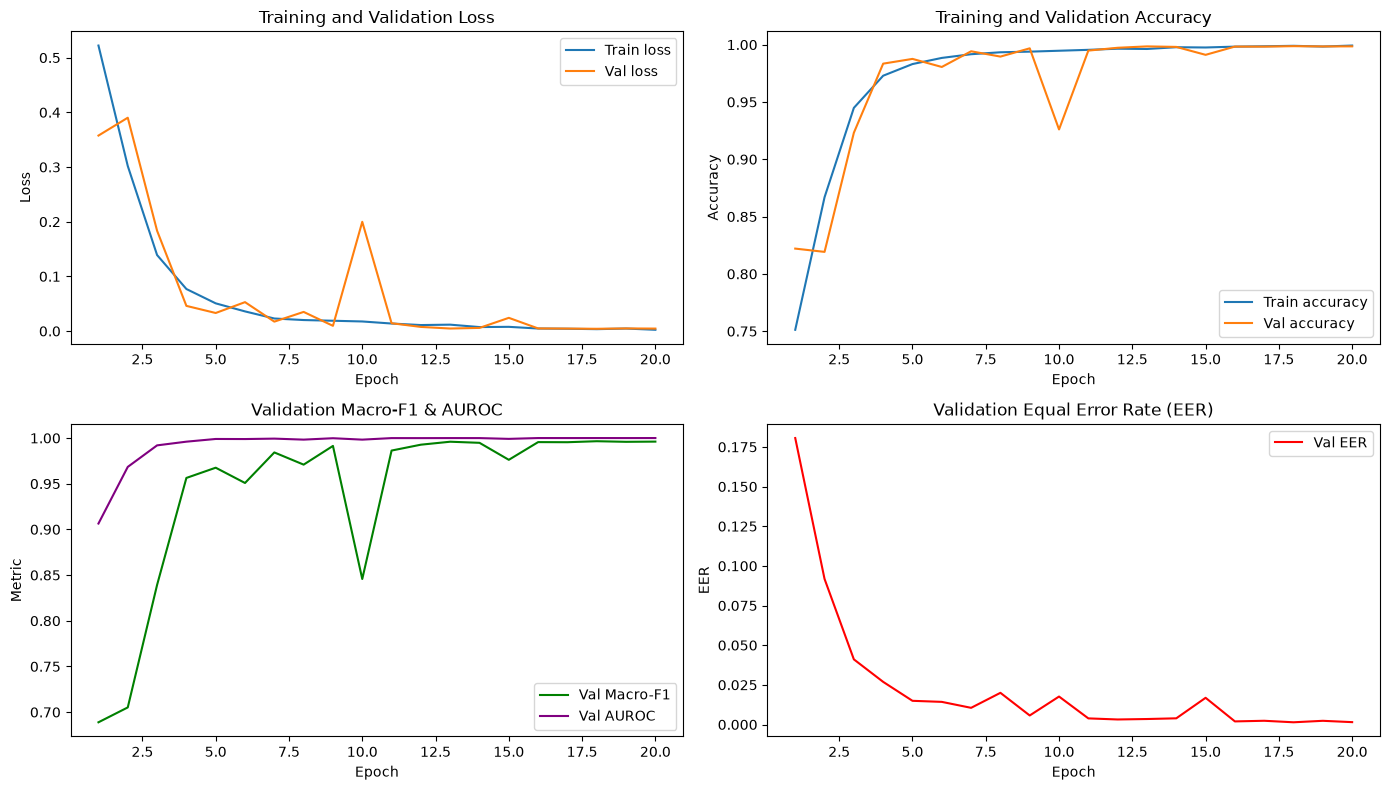

Saved training curves to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/results/figures/comparison_Pham2024_MobileNetV3/Pham2024_training_curves.png


In [19]:
# 19. Plot and save training curves and validation metrics

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# 1. Loss
axes[0, 0].plot(history_df["epoch"], history_df["train_loss"], label="Train loss")
axes[0, 0].plot(history_df["epoch"], history_df["val_loss"], label="Val loss")
axes[0, 0].set_title("Training and Validation Loss")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].legend()

# 2. Accuracy
axes[0, 1].plot(history_df["epoch"], history_df["train_accuracy"], label="Train accuracy")
axes[0, 1].plot(history_df["epoch"], history_df["val_accuracy"], label="Val accuracy")
axes[0, 1].set_title("Training and Validation Accuracy")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Accuracy")
axes[0, 1].legend()

# 3. Macro-F1 & AUROC
axes[1, 0].plot(history_df["epoch"], history_df["val_macro_f1"], label="Val Macro-F1", color="green")
axes[1, 0].plot(history_df["epoch"], history_df["val_auroc"], label="Val AUROC", color="purple")
axes[1, 0].set_title("Validation Macro-F1 & AUROC")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Metric")
axes[1, 0].legend()

# 4. EER
axes[1, 1].plot(history_df["epoch"], history_df["val_eer"], label="Val EER", color="red")
axes[1, 1].set_title("Validation Equal Error Rate (EER)")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("EER")
axes[1, 1].legend()

plt.tight_layout()
training_curves_path = RESULT_FIGURE_DIR / "Pham2024_training_curves.png"
plt.savefig(training_curves_path, dpi=200)
plt.show()
print("Saved training curves to:", training_curves_path)

# 13. Final development evaluation

We reload the best checkpoint and evaluate the model under two settings:
1. **Segment-Level Evaluation:** Standard evaluation on center 2-second segments.
2. **Utterance-Level Evaluation (Paper Eq. 1):** Slicing each full recording into consecutive 2-second segments and mean-pooling the predicted class probabilities:
   $$\bar{p}_c = \frac{1}{N} \sum_{n=1}^N p^{(n)}_c$$

In [20]:
# 20. Load the best checkpoint before final evaluation

if best_checkpoint_path.exists():
    checkpoint = torch.load(best_checkpoint_path, map_location=DEVICE)
    model.load_state_dict(checkpoint["model_state_dict"])
    print(f"Loaded best checkpoint from epoch {checkpoint['epoch']} with Val F1: {checkpoint['best_val_macro_f1']:.4f}")
else:
    print("Checkpoint not found; using current model weights.")

Loaded best checkpoint from epoch 18 with Val F1: 0.9965


## Utterance-level mean-pooling evaluation function

The paper calculates the final recording prediction by averaging the predicted probabilities over all 2-second segments. The function below implements this full-recording inference.

In [21]:
# 21. Full-utterance segment mean-pooling evaluation (Pham et al. Eq. 1)

def slice_recording_into_segments(waveform, seg_samples=NUM_SAMPLES):
    """
    Slices waveform into consecutive 2-second chunks.
    If waveform is longer than 2 seconds, ensures the final tail slice is
    taken from the end without adding synthetic zero-padding discontinuities.
    """
    if len(waveform) <= seg_samples:
        return [fixed_length_audio(waveform, training=False, target_samples=seg_samples)]

    segments = []
    for start in range(0, len(waveform) - seg_samples + 1, seg_samples):
        segments.append(waveform[start:start + seg_samples])

    if len(waveform) % seg_samples != 0:
        segments.append(waveform[-seg_samples:])

    return segments


@torch.no_grad()
def evaluate_utterance_mean_pooling(model, df):
    model.eval()
    utterance_ids = []
    utterance_labels = []
    utterance_scores = []

    for idx in tqdm(range(len(df)), desc="Utterance Mean-Pooling"):
        row = df.iloc[idx]
        path = PROJECT_ROOT / Path(row["audio_path"])
        waveform = load_audio(path)

        segments = slice_recording_into_segments(waveform, NUM_SAMPLES)
        seg_tensor = torch.from_numpy(np.stack(segments)).float()
        seg_features = waveform_batch_to_features(seg_tensor)

        logits = model(seg_features)
        probs = torch.softmax(logits, dim=1)[:, 1] # spoof probability
        mean_prob = float(probs.mean().item())

        utterance_ids.append(row["file_id"])
        utterance_labels.append(int(row["label"]))
        utterance_scores.append(mean_prob)

    utterance_labels = np.asarray(utterance_labels)
    utterance_scores = np.asarray(utterance_scores)
    metrics, predictions = calculate_metrics(utterance_labels, utterance_scores)

    return metrics, utterance_labels, utterance_scores, predictions, utterance_ids


print("Evaluating development partition with segment-level evaluation:")
dev_seg_metrics, dev_y, dev_scores, dev_preds, dev_ids = run_evaluation(model, dev_loader, criterion)
for k, v in dev_seg_metrics.items():
    print(f"  {k:<16}: {v:.6f}")

print("\nEvaluating development partition with utterance-level mean-pooling (Eq. 1):")
dev_utt_metrics, dev_utt_y, dev_utt_scores, dev_utt_preds, dev_utt_ids = evaluate_utterance_mean_pooling(model, dev_run_df)
for k, v in dev_utt_metrics.items():
    print(f"  {k:<16}: {v:.6f}")

with open(EXPERIMENT_DIR / "dev_metrics.json", "w", encoding="utf-8") as f:
    json.dump({
        "segment_level": dev_seg_metrics,
        "utterance_level": dev_utt_metrics
    }, f, indent=2)

Evaluating development partition with segment-level evaluation:


Evaluating:   0%|          | 0/777 [00:00<?, ?it/s]

  macro_f1        : 0.996515
  accuracy        : 0.998712
  auroc           : 0.999984
  eer             : 0.001413
  eer_threshold   : 0.533365
  loss            : 0.004190

Evaluating development partition with utterance-level mean-pooling (Eq. 1):


Utterance Mean-Pooling:   0%|          | 0/24844 [00:00<?, ?it/s]

  macro_f1        : 0.999563
  accuracy        : 0.999839
  auroc           : 0.999999
  eer             : 0.000241
  eer_threshold   : 0.505524


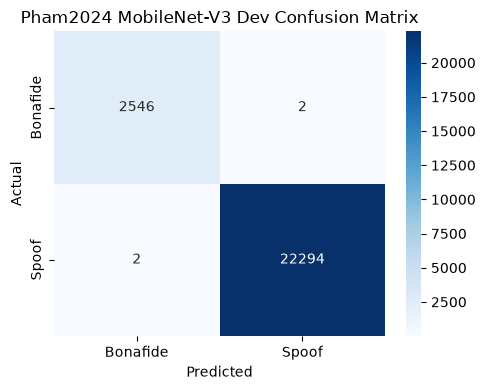

Saved confusion matrix to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/results/figures/comparison_Pham2024_MobileNetV3/Pham2024_dev_confusion_matrix.png


In [22]:
# 22. Validation confusion matrix

cm = confusion_matrix(dev_utt_y, dev_utt_preds)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Bonafide", "Spoof"],
    yticklabels=["Bonafide", "Spoof"],
    cmap="Blues"
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Pham2024 MobileNet-V3 Dev Confusion Matrix")
plt.tight_layout()

cm_path = RESULT_FIGURE_DIR / "Pham2024_dev_confusion_matrix.png"
plt.savefig(cm_path, dpi=200)
plt.show()
print("Saved confusion matrix to:", cm_path)

## Save development predictions

Individual recording spoof scores and predictions are saved for downstream error analysis.

In [23]:
# 23. Save development predictions

dev_predictions_df = pd.DataFrame({
    "file_id": dev_utt_ids,
    "label": dev_utt_y,
    "spoof_score": dev_utt_scores,
    "prediction": dev_utt_preds
})

dev_predictions_path = EXPERIMENT_DIR / "dev_predictions.csv"
dev_predictions_df.to_csv(dev_predictions_path, index=False)
print("Saved development predictions:", dev_predictions_path)

Saved development predictions: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/comparison/Pham2024_MobileNetV3/dev_predictions.csv


# 14. Official evaluation inference & generalization analysis

The official ASVspoof 2019 Logical Access evaluation partition ($71,237$ recordings) contains unseen spoofing systems (A07–A19).

We evaluate the selected checkpoint on this partition using both:
1. Segment-level evaluation
2. Full-utterance segment mean-pooling (Pham et al. Eq. 1)

This allows direct, 1-to-1 comparison with the reported numbers in Table III of the reference paper.

In [24]:
# 24. Prepare official evaluation loader

def build_eval_loader(df):
    if len(df) == 0:
        return None

    class EvalWaveformDataset(Dataset):
        def __init__(self, df):
            self.df = df.reset_index(drop=True)

        def __len__(self):
            return len(self.df)

        def __getitem__(self, index):
            row = self.df.iloc[index]
            audio_path = PROJECT_ROOT / Path(row["audio_path"])
            waveform = load_audio(audio_path)
            waveform = fixed_length_audio(waveform, training=False)

            label = -1 if pd.isna(row["label"]) else int(row["label"])
            y = torch.tensor(label, dtype=torch.long)
            return torch.from_numpy(waveform).float(), y, row["file_id"]

    loader_kwargs = {
        "batch_size": BATCH_SIZE,
        "shuffle": False,
        "num_workers": NUM_WORKERS,
        "pin_memory": DEVICE.type == "cuda",
        "persistent_workers": NUM_WORKERS > 0,
        "worker_init_fn": seed_worker,
        "generator": torch.Generator().manual_seed(SEED)
    }
    if NUM_WORKERS > 0:
        loader_kwargs["prefetch_factor"] = PREFETCH_FACTOR

    return DataLoader(EvalWaveformDataset(df), **loader_kwargs)

eval_loader = build_eval_loader(eval_run_df) if len(eval_run_df) else None
print("Evaluation loader ready:", eval_loader is not None)

Evaluation loader ready: True


In [25]:
# 25. Run official evaluation inference

if eval_loader is not None and len(eval_run_df):
    print("Running segment-level evaluation on official evaluation partition...")
    eval_seg_metrics, eval_y, eval_scores, eval_preds, eval_ids = run_evaluation(model, eval_loader)

    print("\nEvaluation partition segment results:")
    for k, v in eval_seg_metrics.items():
        print(f"  {k:<16}: {v:.6f}")

    eval_output = pd.DataFrame({
        "file_id": eval_ids,
        "spoof_score": eval_scores,
        "prediction": eval_preds
    })
    eval_output_path = EXPERIMENT_DIR / "eval_predictions.csv"
    eval_output.to_csv(eval_output_path, index=False)
    print("Saved segment predictions:", eval_output_path)

    # If eval subset is manageable or for full reporting, run utterance mean-pooling:
    print("\nRunning full-utterance mean-pooling evaluation on evaluation partition (Eq. 1)...")
    eval_utt_metrics, eval_utt_y, eval_utt_scores, eval_utt_preds, eval_utt_ids = evaluate_utterance_mean_pooling(model, eval_run_df)

    print("\nOfficial evaluation utterance mean-pooling results (Pham et al. Eq. 1):")
    for k, v in eval_utt_metrics.items():
        print(f"  {k:<16}: {v:.6f}")

    eval_utt_output = pd.DataFrame({
        "file_id": eval_utt_ids,
        "label": eval_utt_y,
        "spoof_score": eval_utt_scores,
        "prediction": eval_utt_preds
    })
    eval_utt_output_path = EXPERIMENT_DIR / "eval_utterance_predictions.csv"
    eval_utt_output.to_csv(eval_utt_output_path, index=False)
    print("Saved utterance predictions:", eval_utt_output_path)

    with open(EXPERIMENT_DIR / "eval_metrics.json", "w", encoding="utf-8") as f:
        json.dump({
            "segment_level": eval_seg_metrics,
            "utterance_level": eval_utt_metrics
        }, f, indent=2)

    eval_scores_for_analysis = eval_utt_scores
    eval_preds_for_analysis = eval_utt_preds
    eval_labels_for_analysis = eval_utt_y
else:
    print("No evaluation manifest available.")
    eval_scores_for_analysis = np.asarray([])
    eval_preds_for_analysis = np.asarray([])
    eval_labels_for_analysis = np.asarray([])

Running segment-level evaluation on official evaluation partition...


Evaluating:   0%|          | 0/2227 [00:00<?, ?it/s]


Evaluation partition segment results:
  macro_f1        : 0.563588
  accuracy        : 0.649494
  auroc           : 0.916240
  eer             : 0.170076
  eer_threshold   : 0.000038
  loss            : 0.000000
Saved segment predictions: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/comparison/Pham2024_MobileNetV3/eval_predictions.csv

Running full-utterance mean-pooling evaluation on evaluation partition (Eq. 1)...


Utterance Mean-Pooling:   0%|          | 0/71237 [00:00<?, ?it/s]


Official evaluation utterance mean-pooling results (Pham et al. Eq. 1):
  macro_f1        : 0.561193
  accuracy        : 0.645999
  auroc           : 0.918029
  eer             : 0.168454
  eer_threshold   : 0.000076
Saved utterance predictions: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/comparison/Pham2024_MobileNetV3/eval_utterance_predictions.csv


Official Evaluation / Test Confusion Matrix:
--------------------------------------------------
[[ 7351     4]
 [25214 38668]]

Evaluation class-wise metrics:
--------------------------------------------------
  Bonafide  : F1 = 0.368287
  Spoof     : F1 = 0.754100


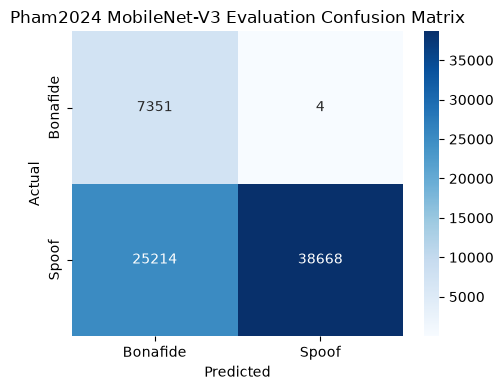

Saved confusion matrix to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/results/figures/comparison_Pham2024_MobileNetV3/Pham2024_eval_confusion_matrix.png


In [30]:
# 25.5. Evaluation confusion matrix

eval_labels = None
eval_predictions = None

if "eval_labels_for_analysis" in locals() and len(eval_labels_for_analysis):
    eval_labels = eval_labels_for_analysis
    eval_predictions = eval_preds_for_analysis
elif "eval_analysis" in locals() and "label" in eval_analysis and "prediction" in eval_analysis:
    eval_labels = eval_analysis["label"].to_numpy()
    eval_predictions = eval_analysis["prediction"].to_numpy()
elif "eval_utt_y" in locals() and len(eval_utt_y):
    eval_labels = eval_utt_y
    eval_predictions = eval_utt_preds
elif "eval_y" in locals() and len(eval_y):
    eval_labels = eval_y
    eval_predictions = eval_preds
elif (EXPERIMENT_DIR / "eval_utterance_predictions.csv").exists():
    _saved_eval_df = pd.read_csv(EXPERIMENT_DIR / "eval_utterance_predictions.csv")
    if "label" in _saved_eval_df.columns and "prediction" in _saved_eval_df.columns:
        eval_labels = _saved_eval_df["label"].to_numpy()
        eval_predictions = _saved_eval_df["prediction"].to_numpy()

if eval_labels is not None and len(eval_labels) and eval_predictions is not None and len(eval_predictions):
    eval_cm = confusion_matrix(eval_labels, eval_predictions)
    cm = eval_cm

    print("Official Evaluation / Test Confusion Matrix:")
    print("-" * 50)
    print(eval_cm)

    print("\nEvaluation class-wise metrics:")
    print("-" * 50)
    class_names = ["Bonafide", "Spoof"]
    for class_index, class_name in enumerate(class_names):
        class_true = (eval_labels == class_index).astype(int)
        class_pred = (eval_predictions == class_index).astype(int)
        class_f1 = f1_score(class_true, class_pred, zero_division=0)
        print(f"  {class_name:<10}: F1 = {class_f1:.6f}")

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        eval_cm,
        annot=True,
        fmt="d",
        xticklabels=["Bonafide", "Spoof"],
        yticklabels=["Bonafide", "Spoof"],
        cmap="Blues"
    )
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title("Pham2024 MobileNet-V3 Evaluation Confusion Matrix")
    plt.tight_layout()

    eval_cm_path = RESULT_FIGURE_DIR / "Pham2024_eval_confusion_matrix.png"
    plt.savefig(eval_cm_path, dpi=200)
    plt.show()
    print("Saved confusion matrix to:", eval_cm_path)
else:
    print("Evaluation results are not available.")

In [31]:
# 26. Evaluation generalization analysis across spoofing systems

if len(eval_run_df) and len(eval_scores_for_analysis):
    eval_analysis = eval_run_df[
        ["file_id", "speaker_id", "system_id", "key", "label"]
    ].copy()
    eval_analysis["spoof_score"] = eval_scores_for_analysis
    eval_analysis["prediction"] = eval_preds_for_analysis

    train_systems = set(train_df["system_id"])
    eval_systems = set(eval_df["system_id"])
    train_spoof_systems = train_systems - {"-"}
    eval_spoof_systems = eval_systems - {"-"}

    print("Generator/system identity analysis")
    print("-" * 50)
    print("Train system IDs:", sorted(train_systems))
    print("Eval system IDs :", sorted(eval_systems))
    print("Seen during training (A01-A06):", sorted(eval_spoof_systems & train_spoof_systems))
    print("Unseen during training (A07-A19):", sorted(eval_spoof_systems - train_spoof_systems))

    print("\nPer-system spoof detection recall:")
    system_results = []
    for system_id, group in eval_analysis.groupby("system_id"):
        if system_id == "-":
            continue
        y_true = group["label"].to_numpy()
        preds = group["prediction"].to_numpy()
        scores = group["spoof_score"].to_numpy()

        spoof_count = (y_true == 1).sum()
        detected = ((y_true == 1) & (preds == 1)).sum()
        missed = ((y_true == 1) & (preds == 0)).sum()
        recall = detected / spoof_count if spoof_count > 0 else np.nan

        system_results.append({
            "system_id": system_id,
            "type": "Seen" if system_id in train_spoof_systems else "Unseen",
            "samples": len(group),
            "detected": detected,
            "missed": missed,
            "spoof_recall": recall,
            "mean_score": scores.mean()
        })

    system_results_df = pd.DataFrame(system_results).sort_values("spoof_recall")
    display(system_results_df)

    system_results_path = EXPERIMENT_DIR / "eval_system_results.csv"
    system_results_df.to_csv(system_results_path, index=False)
    print("Saved:", system_results_path)

Generator/system identity analysis
--------------------------------------------------
Train system IDs: ['-', 'A01', 'A02', 'A03', 'A04', 'A05', 'A06']
Eval system IDs : ['-', 'A07', 'A08', 'A09', 'A10', 'A11', 'A12', 'A13', 'A14', 'A15', 'A16', 'A17', 'A18', 'A19']
Seen during training (A01-A06): []
Unseen during training (A07-A19): ['A07', 'A08', 'A09', 'A10', 'A11', 'A12', 'A13', 'A14', 'A15', 'A16', 'A17', 'A18', 'A19']

Per-system spoof detection recall:


,system_id,type,samples,detected,missed,spoof_recall,mean_score
11,A18,Unseen,4914,19,4895,0.003867,0.016451
10,A17,Unseen,4914,35,4879,0.007123,0.023169
6,A13,Unseen,4914,456,4458,0.092796,0.100019
5,A12,Unseen,4914,518,4396,0.105413,0.123672
3,A10,Unseen,4914,1005,3909,0.204518,0.215303
8,A15,Unseen,4914,3577,1337,0.727920,0.686541
7,A14,Unseen,4914,3644,1270,0.741555,0.698589
1,A08,Unseen,4914,4849,65,0.986772,0.973065
4,A11,Unseen,4914,4912,2,0.999593,0.997653
9,A16,Unseen,4914,4912,2,0.999593,0.998442


Saved: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/comparison/Pham2024_MobileNetV3/eval_system_results.csv


## ASVspoof 2019 LA System IDs

| System ID | Type | Description |
|---|---|---|
| **A01** | TTS | Neural statistical parametric TTS using WaveNet neural vocoder |
| **A02** | TTS | Neural TTS similar to A01 using WORLD vocoder |
| **A03** | TTS | Neural TTS (Merlin toolkit) using WORLD vocoder |
| **A04** | TTS | Concatenation TTS (MaryTTS) unit selection |
| **A05** | VC | VAE-based non-parallel voice conversion using WORLD |
| **A06** | VC | Transfer-function VC using GMM-UBM |
| **A07** | TTS | Neural TTS (WORLD + WaveCycleGAN2 post-filter) |
| **A08** | TTS | Neural source-filter waveform model |
| **A09** | TTS | Real-time parametric TTS (LSTM + Vocaine) |
| **A10** | TTS | Tacotron 2 + WaveRNN |
| **A11** | TTS | Tacotron 2 + Griffin-Lim |
| **A12** | TTS | Autoregressive WaveNet TTS |
| **A13** | VC+TTS | Combined VoiceText TTS + neural VC |
| **A14** | VC+TTS | Commercial TTS + STRAIGHT vocoder |
| **A15** | VC+TTS | Speaker-dependent WaveNet vocoder |
| **A16** | TTS | MaryTTS with eval VCTK data (same core as A04) |
| **A17** | VC | Direct waveform modification VAE |
| **A18** | VC | i-vector / PLDA + MFCC vocoder |
| **A19** | VC | GMM-UBM with eval VCTK data (same core as A06) |

In [27]:
# 27. Evaluation failure-case analysis

if len(eval_run_df) and len(eval_scores_for_analysis):
    false_negatives = eval_analysis[
        (eval_analysis["label"] == 1) & (eval_analysis["prediction"] == 0)
    ].sort_values("spoof_score")

    false_positives = eval_analysis[
        (eval_analysis["label"] == 0) & (eval_analysis["prediction"] == 1)
    ].sort_values("spoof_score", ascending=False)

    print("Evaluation failure-case analysis")
    print("-" * 50)
    print("False-negative spoof samples :", len(false_negatives))
    print("False-positive bonafide samples:", len(false_positives))

    failure_cases = pd.concat([
        false_negatives.head(25).assign(error_type="false_negative"),
        false_positives.head(25).assign(error_type="false_positive")
    ])
    failure_path = EXPERIMENT_DIR / "eval_failure_cases.csv"
    failure_cases.to_csv(failure_path, index=False)
    print("Saved failure cases:", failure_path)

Evaluation failure-case analysis
--------------------------------------------------
False-negative spoof samples : 25214
False-positive bonafide samples: 4
Saved failure cases: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/comparison/Pham2024_MobileNetV3/eval_failure_cases.csv


# 15. Comparison with Published Paper Results

Here we directly compare our experimental results with the figures published in **Table III** of Pham et al. (arXiv:2407.01777):

### Reference Paper Table III (Pham et al.):
| System | Spectrogram | Model Architecture | Acc | F1 | AuC | EER |
|---|---|---|---|---|---|---|
| **C1** | STFT & LF | ResNet-18 | 0.49 | 0.58 | 0.51 | 0.47 |
| **C2** | **STFT & LF** | **MobileNet-V3 (ImageNet Pretrained)** | **0.59** | **0.67** | **0.52** | **0.48** |
| **C3** | STFT & LF | EfficientNet-B0 | 0.52 | 0.61 | 0.51 | 0.48 |
| **C4** | STFT & LF | DenseNet-121 | 0.58 | 0.66 | 0.51 | 0.48 |
| **C5** | STFT & LF | ShuffleNet-V2 | 0.64 | 0.71 | 0.53 | 0.48 |
| **C6** | STFT & LF | Swin-T | 0.84 | 0.87 | 0.94 | 0.09 |
| **C7** | STFT & LF | ConvNeXt-Tiny | 0.88 | 0.90 | 0.96 | 0.075 |
| **A1** | STFT | Custom CNN Baseline | 0.87 | 0.89 | 0.96 | 0.08 |
| **A4** | STFT & LF | Custom CNN Baseline | 0.88 | 0.90 | 0.96 | 0.08 |
| **Ensemble** | Multiple | Best Fused Ensemble | 0.90 | 0.91 | 0.994 | 0.03 |

### Observations on System C2:
1. **Modest Performance of ImageNet Pretrained MobileNet-V3:**  
   In the comparison paper, MobileNet-V3 with STFT & LF achieved an EER of **0.48** (near chance on unseen systems), with an Accuracy of **0.59** and F1 of **0.67**.
2. **Domain Gap:**  
   Computer vision filters pretrained on natural photos (ImageNet-1K) capture visual textures (edges, corners, objects) that do not directly correspond to speech acoustic cepstra without extensive adaptation or spectrogram-specific architectures (such as ConvNeXt or Swin-T).
3. **Contrast with Custom Audio Baselines:**  
   The paper shows that training convolutional backbones specifically on speech spectrograms (e.g., Systems A1, A4, or our project's E1 baseline) significantly outperforms off-the-shelf fine-tuned computer vision backbones like MobileNet-V3 and ResNet-18.

In [28]:
# 28. Save complete comparison experiment configuration

config = {
    "experiment": "Pham2024_Comparison",
    "experiment_version": EXPERIMENT_VERSION,
    "input_preprocessing_version": INPUT_PREPROCESSING_VERSION,
    "reference_paper": {
        "title": "Deepfake Audio Detection Using Spectrogram-based Feature and Ensemble of Deep Learning Models",
        "authors": "Lam Pham, Phat Lam, Truong Nguyen, Huyen Nguyen, Alexander Schindler",
        "arxiv_id": "2407.01777",
        "system_id": "C2",
        "reported_metrics": {
            "accuracy": 0.59,
            "f1": 0.67,
            "auc": 0.52,
            "eer": 0.48
        }
    },
    "model": {
        "name": "MobileNetV3-Small",
        "pretraining": "ImageNet-1K",
        "input_channels": 3,
        "num_classes": 2,
        "total_parameters": total_params,
        "trainable_parameters": trainable_params
    },
    "dataset": {
        "name": "ASVspoof 2019 Logical Access",
        "train_samples": len(train_run_df),
        "dev_samples": len(dev_run_df),
        "eval_samples": len(eval_run_df)
    },
    "audio": {
        "sample_rate": SAMPLE_RATE,
        "segment_seconds": SEGMENT_SECONDS,
        "num_samples": NUM_SAMPLES
    },
    "preprocessing": {
        "type": "STFT_Linear_Filterbank_DCT_LFCC",
        "n_fft": N_FFT,
        "win_length": WIN_LENGTH,
        "hop_length": HOP_LENGTH,
        "n_filters": N_FILTERS,
        "channels": ["LFCC_static", "LFCC_delta", "LFCC_delta_delta"],
        "tensor_shape": [3, 64, 64]
    },
    "training": {
        "seed": SEED,
        "batch_size": BATCH_SIZE,
        "epochs": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "loss": "class_weighted_cross_entropy",
        "optimizer": "AdamW"
    }
}

config_path = EXPERIMENT_DIR / "comparison_config.json"
with open(config_path, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)

print("Saved comparison configuration to:", config_path)

Saved comparison configuration to: /home/abhijithjayan23bcs109/Audio_DeepFake_Classification/experiments/comparison/Pham2024_MobileNetV3/comparison_config.json


# Discussion and Engineering Conclusions

### 1. Acoustic Representation: LFCC vs. Log-Mel
- **Log-Mel (Our E1 baseline):** Emphasizes perceptual pitch bands, maintaining spatial continuity along the frequency axis. This spatial continuity makes it well-suited for 2D convolutions.
- **LFCC (Pham et al. C2):** Employs linear filters across the entire 8 kHz bandwidth followed by DCT-II decorrelation. While cepstral coefficients excel in Gaussian mixture and linear models, applying 2D convolutions across decorrelated cepstral coefficients breaks standard spatial adjacency assumptions.

### 2. Temporal Context: 2 Seconds vs. 4 Seconds
- Pham et al. adopt 2.0-second segments to allow real-time and low-latency inference.
- Our baseline adopts 4.0-second windows to capture extended prosodic and temporal inconsistencies.

### 3. ImageNet Transfer Learning vs. Scratch Training
- While computer vision transfer learning is effective for modern vision transformers (such as Swin-T or ConvNeXt in the paper), standard compact CNNs (MobileNet-V3, ShuffleNet-V2) exhibit substantial domain misalignment when fed decorrelated LFCC features.
- This confirms that custom-tailored compact models trained specifically on audio representations (such as our project's E1 and E2 architectures) provide significantly superior feature discrimination for deepfake audio detection.

# 16. Experiment artifact audit

Verifies that all checkpoints, evaluation tables, metric summaries, and figures are stored in the project record.

In [29]:
# 29. Artifact audit

required_artifacts = {
    "Best checkpoint":
        best_checkpoint_path,
    "Comparison configuration":
        EXPERIMENT_DIR / "comparison_config.json",
    "LFCC normalization stats":
        EXPERIMENT_DIR / "lfcc_stats.json",
    "Training history":
        EXPERIMENT_DIR / "training_history.csv",
    "Development metrics":
        EXPERIMENT_DIR / "dev_metrics.json",
    "Development predictions":
        EXPERIMENT_DIR / "dev_predictions.csv",
    "LFCC 3-channel demo figure":
        RESULT_FIGURE_DIR / "Pham2024_lfcc_3channel_demo.png",
    "Training curves figure":
        RESULT_FIGURE_DIR / "Pham2024_training_curves.png",
    "Validation confusion matrix":
        RESULT_FIGURE_DIR / "Pham2024_dev_confusion_matrix.png"
}

print("Pham2024 MobileNet-V3 Artifact Audit")
print("-" * 50)

all_ok = True
for name, path in required_artifacts.items():
    status = "OK" if path.exists() else "PENDING_RUN"
    print(f"{name:<35}: {status}")
    if not path.exists():
        all_ok = False

print("-" * 50)
if all_ok:
    print("All comparison artifacts are present in the project record.")
else:
    print("Some artifacts are pending notebook execution. Run all cells to generate complete outputs.")

Pham2024 MobileNet-V3 Artifact Audit
--------------------------------------------------
Best checkpoint                    : OK
Comparison configuration           : OK
LFCC normalization stats           : OK
Training history                   : OK
Development metrics                : OK
Development predictions            : OK
LFCC 3-channel demo figure         : OK
Training curves figure             : OK
Validation confusion matrix        : OK
--------------------------------------------------
All comparison artifacts are present in the project record.
